In [1]:
import numpy as np
import pandas as pd


In [2]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame = True)

In [3]:
df = iris.frame

In [4]:
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [5]:
df.tail()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2
149,5.9,3.0,5.1,1.8,2


In [6]:
df = df[df['target'] != 0] [['sepal width (cm)', 'petal length (cm)', 'target']]

In [7]:
df.head()

,sepal width (cm),petal length (cm),target
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

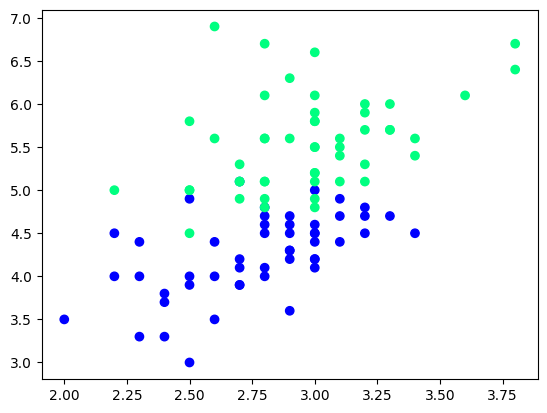

In [9]:
plt.scatter(df['sepal width (cm)'], df['petal length (cm)'], c = df['target'], cmap='winter')

In [10]:
df_train = df.iloc[:60,:].sample(10)
df_train

,sepal width (cm),petal length (cm),target
92,2.6,4.0,1
80,2.4,3.8,1
98,2.5,3.0,1
77,3.0,5.0,1
105,3.0,6.6,2
76,2.8,4.8,1
52,3.1,4.9,1
99,2.8,4.1,1
87,2.3,4.4,1
53,2.3,4.0,1


In [11]:
# Taking only 10 rows for training :
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [12]:
df

,sepal width (cm),petal length (cm),target
126,2.8,4.8,2
66,3.0,4.5,1
137,3.1,5.5,2
89,2.5,4.0,1
132,2.8,5.6,2
...,...,...,...
68,2.2,4.5,1
148,3.4,5.4,2
117,3.8,6.7,2
74,2.9,4.3,1


In [13]:
df_train

,sepal width (cm),petal length (cm),target
83,2.7,5.1,1
108,2.5,5.8,2
99,2.8,4.1,1
94,2.7,4.2,1
82,2.7,3.9,1
104,3.0,5.8,2
52,3.1,4.9,1
60,2.0,3.5,1
145,3.0,5.2,2
112,3.0,5.5,2


In [14]:
df_val

,sepal width (cm),petal length (cm),target
69,2.5,3.9,1
110,3.2,5.1,2
87,2.3,4.4,1
124,3.3,5.7,2
95,3.0,4.2,1


In [15]:
df_test

,sepal width (cm),petal length (cm),target
76,2.8,4.8,1
71,2.8,4.0,1
118,2.6,6.9,2
70,3.2,4.8,1
98,2.5,3.0,1


In [16]:
X_test = df_val.iloc[:,0:2].values
Y_test = df_val.iloc[:,-1].values 

In [17]:
X_test

array([[2.5, 3.9],
       [3.2, 5.1],
       [2.3, 4.4],
       [3.3, 5.7],
       [3. , 4.2]])

In [18]:
Y_test

array([1, 2, 1, 2, 1])

### 1. Bagging :

In [19]:
# Data for Tree 1

df_bag = df_train.sample(8, replace = True)

X = df_bag.iloc[:,0:2]   # first two columns
Y = df_bag.iloc[:,-1]    # last column

df_bag


,sepal width (cm),petal length (cm),target
82,2.7,3.9,1
82,2.7,3.9,1
94,2.7,4.2,1
104,3.0,5.8,2
94,2.7,4.2,1
99,2.8,4.1,1
112,3.0,5.5,2
83,2.7,5.1,1


In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [21]:
dt_bag1 = DecisionTreeClassifier()    # max_depth = None

In [22]:
def evaluate(clf, X, Y):
    clf.fit(X, Y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, Y.values, clf=clf, legend=2)
    Y_pred = clf.predict(X_test)
    print(accuracy_score(Y_test,Y_pred))
    

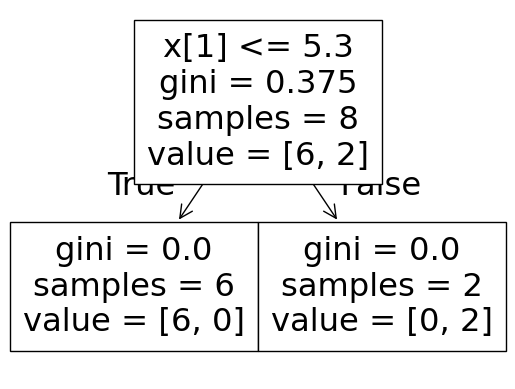

C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


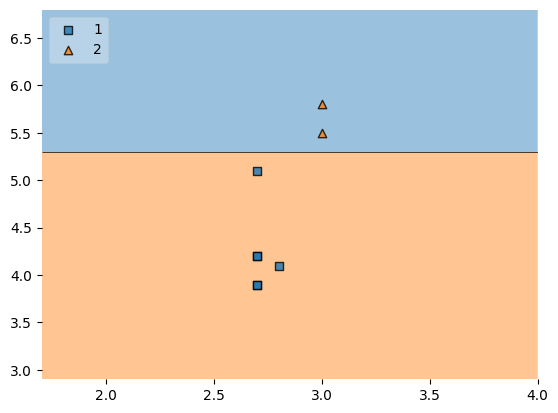

In [23]:
evaluate(dt_bag1, X, Y)

In [24]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
Y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal width (cm),petal length (cm),target
52,3.1,4.9,1
83,2.7,5.1,1
83,2.7,5.1,1
99,2.8,4.1,1
52,3.1,4.9,1
94,2.7,4.2,1
104,3.0,5.8,2
99,2.8,4.1,1


In [25]:
dt_bag2 = DecisionTreeClassifier()

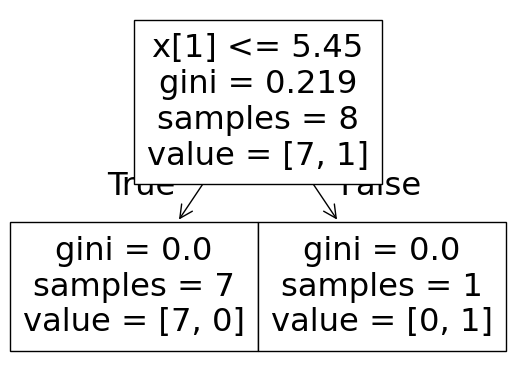

C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


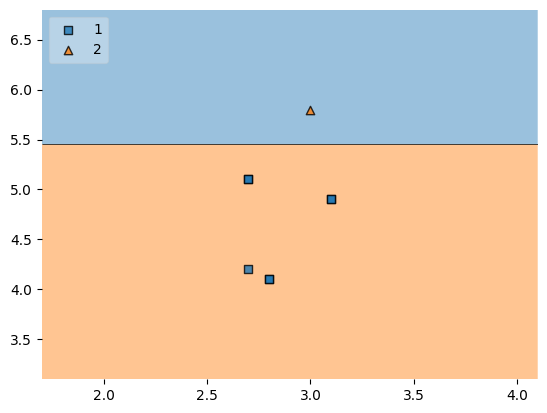

In [26]:
evaluate(dt_bag2, X, Y)

In [27]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
Y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal width (cm),petal length (cm),target
104,3.0,5.8,2
82,2.7,3.9,1
112,3.0,5.5,2
83,2.7,5.1,1
108,2.5,5.8,2
108,2.5,5.8,2
108,2.5,5.8,2
94,2.7,4.2,1


In [28]:
dt_bag3 = DecisionTreeClassifier()

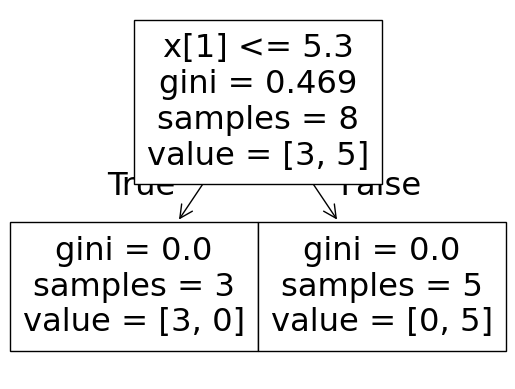

C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


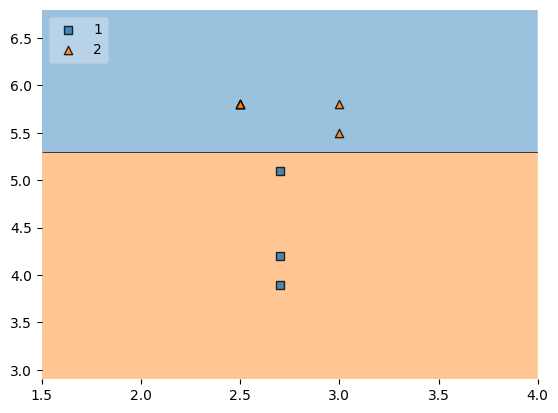

In [29]:
evaluate(dt_bag3, X, Y)

### Predict :


In [30]:
df_test

,sepal width (cm),petal length (cm),target
76,2.8,4.8,1
71,2.8,4.0,1
118,2.6,6.9,2
70,3.2,4.8,1
98,2.5,3.0,1


In [31]:
print("Predictor 1",dt_bag1.predict(np.array([3.1, 4.4]).reshape(1, 2)))
print("Predictor 2",dt_bag2.predict(np.array([3.1, 4.4]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([3.1, 4.4]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [1]
Predictor 3 [1]


C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
C:\Users\amank\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


### Pasting : without replacement

In [32]:
# Row sampling without replacement
df_train

,sepal width (cm),petal length (cm),target
83,2.7,5.1,1
108,2.5,5.8,2
99,2.8,4.1,1
94,2.7,4.2,1
82,2.7,3.9,1
104,3.0,5.8,2
52,3.1,4.9,1
60,2.0,3.5,1
145,3.0,5.2,2
112,3.0,5.5,2


In [33]:
df_train.sample(8)

,sepal width (cm),petal length (cm),target
104,3.0,5.8,2
83,2.7,5.1,1
112,3.0,5.5,2
60,2.0,3.5,1
108,2.5,5.8,2
52,3.1,4.9,1
99,2.8,4.1,1
94,2.7,4.2,1


### Random Subspaces : (Only column sampling with or without replacement)

In [34]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame = True)

In [35]:
df1 = iris.frame

In [36]:
df1.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [37]:
df1.sample(2, replace=True, axis=1)

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


### Random Patches : (both row and column sampling allowed, with or without replacement)

In [38]:
df1

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [39]:
df1.sample(8, replace=True).sample(2, replace=True, axis=1)

,petal length (cm),sepal length (cm)
52,4.9,6.9
121,4.9,5.6
67,4.1,5.8
69,3.9,5.6
70,4.8,5.9
19,1.5,5.1
138,4.8,6.0
7,1.5,5.0
